# Air Quality Time Series Analysis

This project explores hourly air-quality sensor readings. The goal is
to predict the next hour's carbon monoxide concentration using information
available through the current hour.

I will examine time patterns, missing readings, and anomalies, then prepare
features and compare models using chronological training, validation, and
test periods.

In [20]:
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))
raw_bytes = uploaded[filename]

header = raw_bytes.decode("utf-8-sig").splitlines()[0]

if ";" in header:
    air_raw = pd.read_csv(
        io.BytesIO(raw_bytes),
        sep=";",
        decimal=","
    )
else:
    air_raw = pd.read_csv(io.BytesIO(raw_bytes))

print("Raw dataset shape:", air_raw.shape)
print("Columns:", air_raw.columns.tolist())
display(air_raw.head())

Saving AirQuality.csv to AirQuality (3).csv
Raw dataset shape: (9471, 17)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.60,"1,360.00",150.00,11.90,"1,046.00",166.00,"1,056.00",113.00,"1,692.00","1,268.00",13.60,48.90,0.76,NaN,NaN
1,10/03/2004,19.00.00,2.00,"1,292.00",112.00,9.40,955.00,103.00,"1,174.00",92.00,"1,559.00",972.00,13.30,47.70,0.73,NaN,NaN
2,10/03/2004,20.00.00,2.20,"1,402.00",88.00,9.00,939.00,131.00,"1,140.00",114.00,"1,555.00","1,074.00",11.90,54.00,0.75,NaN,NaN
3,10/03/2004,21.00.00,2.20,"1,376.00",80.00,9.20,948.00,172.00,"1,092.00",122.00,"1,584.00","1,203.00",11.00,60.00,0.79,NaN,NaN
4,10/03/2004,22.00.00,1.60,"1,272.00",51.00,6.50,836.00,131.00,"1,205.00",116.00,"1,490.00","1,110.00",11.20,59.60,0.79,NaN,NaN


In [21]:
numeric_check = air_raw.apply(pd.to_numeric, errors="coerce")

initial_quality = pd.DataFrame({
    "data_type": air_raw.dtypes,
    "missing_values": air_raw.isna().sum(),
    "minus_200_values": numeric_check.eq(-200).sum()
})

display(initial_quality)
print("Completely empty rows:", air_raw.isna().all(axis=1).sum())

,data_type,missing_values,minus_200_values
Date,object,114,0
Time,object,114,0
CO(GT),float64,114,1683
PT08.S1(CO),float64,114,366
NMHC(GT),float64,114,8443
C6H6(GT),float64,114,366
PT08.S2(NMHC),float64,114,366
NOx(GT),float64,114,1639
PT08.S3(NOx),float64,114,366
NO2(GT),float64,114,1642


Completely empty rows: 114


## Initial Data Quality Findings

The CSV contains 114 completely empty rows and two completely empty
columns. Missing sensor and pollutant readings are also represented by
the sentinel value -200.

I will remove the empty rows and columns, convert -200 to missing values,
and combine Date and Time into a timestamp. Missing readings will remain
unfilled during initial exploration.

In [22]:
air = air_raw.dropna(how="all").dropna(axis=1, how="all").copy()

measurement_columns = [
    column for column in air.columns
    if column not in ["Date", "Time"]
]

air[measurement_columns] = air[measurement_columns].replace(
    -200, np.nan
)

timestamp_text = (
    air["Date"].astype(str).str.strip()
    + " "
    + air["Time"].astype(str).str.strip()
)

air["timestamp"] = pd.to_datetime(
    timestamp_text,
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)

print("Unparseable timestamps:", air["timestamp"].isna().sum())
assert air["timestamp"].notna().all(), "Inspect unparseable dates before continuing."

air = air.sort_values("timestamp").set_index("timestamp")
air = air.drop(columns=["Date", "Time"])

print("Usable rows:", len(air))
print("First timestamp:", air.index.min())
print("Last timestamp:", air.index.max())
print("Duplicate timestamps:", air.index.duplicated().sum())

display(
    pd.DataFrame({
        "missing_rows": air.isna().sum(),
        "missing_percent": (air.isna().mean() * 100).round(2)
    }).sort_values("missing_percent", ascending=False)
)

display(
    air.index.to_series().diff().value_counts()
    .rename("interval_count").to_frame()
)

Unparseable timestamps: 0
Usable rows: 9357
First timestamp: 2004-03-10 18:00:00
Last timestamp: 2005-04-04 14:00:00
Duplicate timestamps: 0


,missing_rows,missing_percent
NMHC(GT),8443,90.23
CO(GT),1683,17.99
NO2(GT),1642,17.55
NOx(GT),1639,17.52
PT08.S1(CO),366,3.91
C6H6(GT),366,3.91
PT08.S2(NMHC),366,3.91
PT08.S3(NOx),366,3.91
PT08.S4(NO2),366,3.91
PT08.S5(O3),366,3.91


,interval_count
timestamp,
0 days 01:00:00,9356


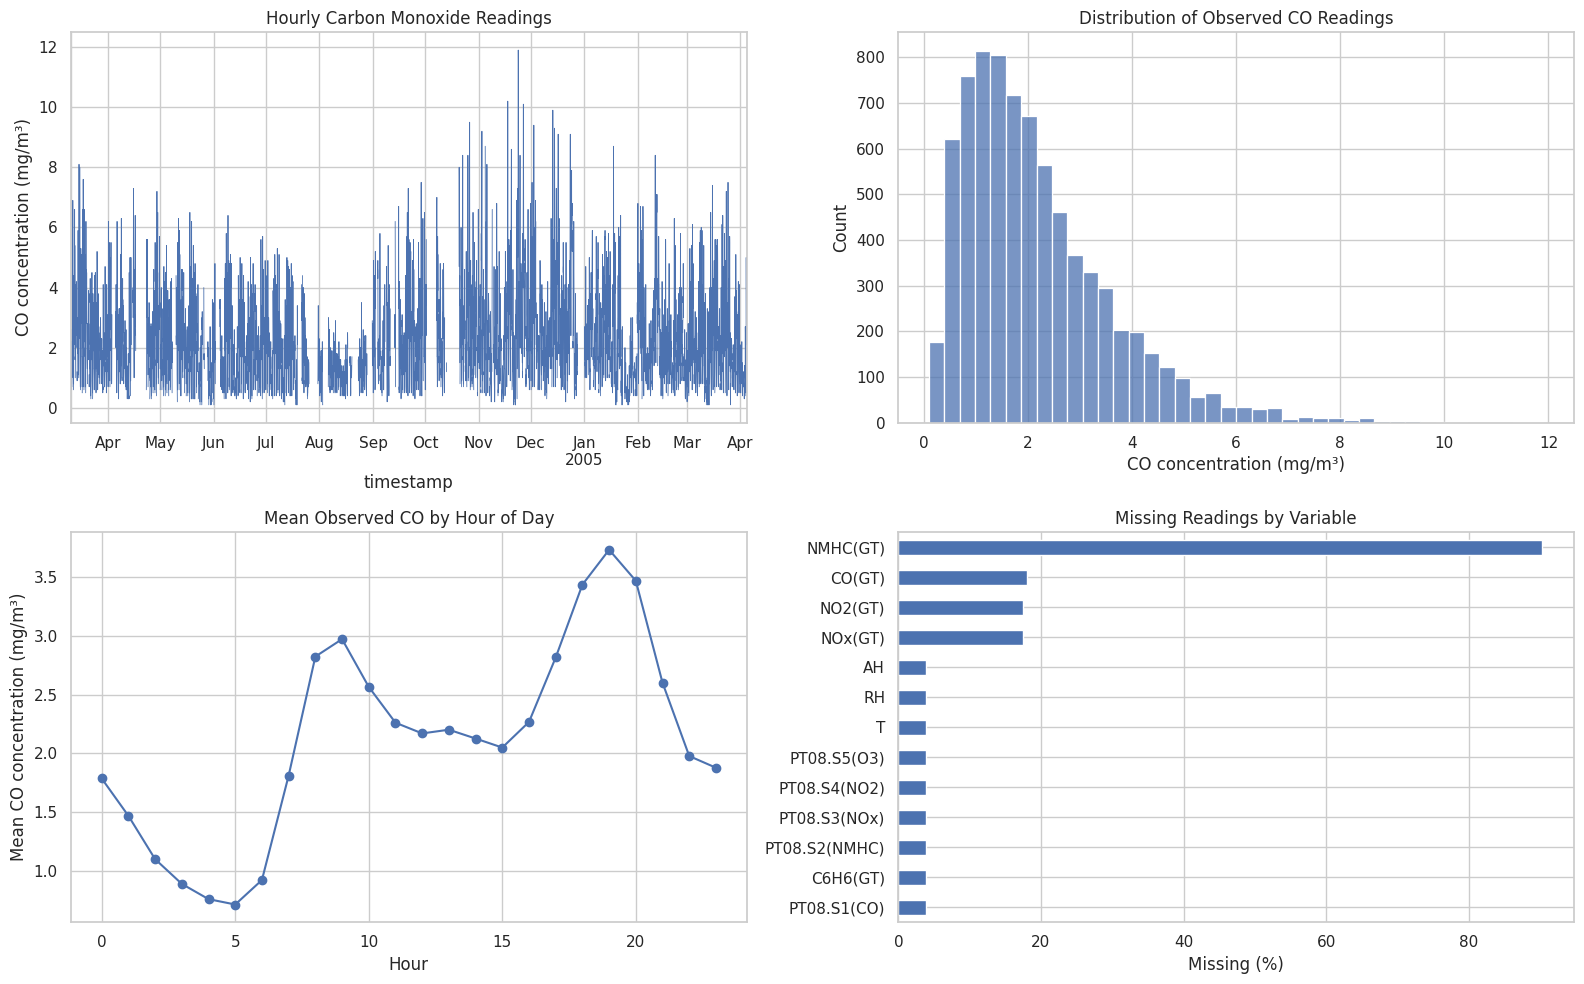

In [23]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

air["CO(GT)"].plot(
    ax=axes[0, 0],
    linewidth=0.6
)
axes[0, 0].set_title("Hourly Carbon Monoxide Readings")
axes[0, 0].set_ylabel("CO concentration (mg/m³)")

sns.histplot(
    air["CO(GT)"].dropna(),
    bins=40,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribution of Observed CO Readings")
axes[0, 1].set_xlabel("CO concentration (mg/m³)")

air.groupby(air.index.hour)["CO(GT)"].mean().plot(
    ax=axes[1, 0],
    marker="o"
)
axes[1, 0].set_title("Mean Observed CO by Hour of Day")
axes[1, 0].set_xlabel("Hour")
axes[1, 0].set_ylabel("Mean CO concentration (mg/m³)")

air.isna().mean().mul(100).sort_values().plot.barh(
    ax=axes[1, 1]
)
axes[1, 1].set_title("Missing Readings by Variable")
axes[1, 1].set_xlabel("Missing (%)")

plt.tight_layout()
plt.show()

## Initial Time-Series Findings

The dataset spans March 10, 2004, through April 4, 2005, with 9,357
consecutive hourly timestamps and no duplicate or unparseable timestamps.

Observed CO concentrations are right-skewed. Average concentrations rise
during the morning and evening, with peaks around 9 AM and 7 PM.
These patterns support using hour-of-day and historical readings as features.

NMHC(GT) is missing for 90.23% of timestamps. CO readings are missing
for 17.99%. Missing target observations will be excluded from supervised
evaluation rather than replaced with estimated values.

In [24]:
train_end = int(len(air) * 0.60)
val_end = int(len(air) * 0.80)

air_train = air.iloc[:train_end].copy()
air_val = air.iloc[train_end:val_end].copy()
air_test = air.iloc[val_end:].copy()

time_split_summary = pd.DataFrame([
    {
        "split": name,
        "hours": len(frame),
        "start": frame.index.min(),
        "end": frame.index.max(),
        "observed_CO": frame["CO(GT)"].notna().sum()
    }
    for name, frame in [
        ("Training", air_train),
        ("Validation", air_val),
        ("Test", air_test)
    ]
])

display(time_split_summary)

assert air_train.index.max() < air_val.index.min()
assert air_val.index.max() < air_test.index.min()

print("Verified: training precedes validation, which precedes testing.")

,split,hours,start,end,observed_CO
0,Training,5614,2004-03-10 18:00:00,2004-10-30 15:00:00,4176
1,Validation,1871,2004-10-30 16:00:00,2005-01-16 14:00:00,1717
2,Test,1872,2005-01-16 15:00:00,2005-04-04 14:00:00,1781


Verified: training precedes validation, which precedes testing.


In [25]:
training_missingness = (
    air_train.isna().mean().mul(100)
    .sort_values(ascending=False)
    .rename("training_missing_percent")
)

display(training_missingness.to_frame())

excluded_measurements = training_missingness[
    training_missingness > 80
].index.tolist()

retained_measurements = [
    column for column in air.columns
    if column not in excluded_measurements
]

print("Excluded measurements (>80% missing in training):",
      excluded_measurements)
print("Retained measurements:", retained_measurements)

,training_missing_percent
NMHC(GT),83.72
CO(GT),25.61
NO2(GT),24.62
NOx(GT),24.56
PT08.S1(CO),2.64
C6H6(GT),2.64
PT08.S2(NMHC),2.64
PT08.S3(NOx),2.64
PT08.S4(NO2),2.64
PT08.S5(O3),2.64


Excluded measurements (>80% missing in training): ['NMHC(GT)']
Retained measurements: ['CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']


## Forecast Features and Missing-Value Handling

Each prediction uses measurements available through hour t to predict
observed CO at hour t+1. Features include current measurements, historical
CO readings, recent CO averages, and calendar patterns.

Predictor gaps will be forward-filled for up to three hours. Remaining
missing predictors will use medians fitted on training features, with
missing-value indicators retained. Future target values will remain
unfilled, and rows without an observed target will be excluded.

Splits are assigned by the target timestamp. Validation and test forecasts
may use readings observed earlier in their respective periods, representing
an hourly forecasting workflow with updated observations.

In [26]:
measurements = air[retained_measurements].copy()
past_filled = measurements.ffill(limit=3)

forecast_features = past_filled.add_suffix("_current")

for column in retained_measurements:
    forecast_features[f"{column}_missing"] = (
        measurements[column].isna().astype(int)
    )

for lag in [1, 2, 3, 24]:
    forecast_features[f"CO_lag_{lag}h"] = (
        past_filled["CO(GT)"].shift(lag)
    )

for window in [3, 6, 24]:
    forecast_features[f"CO_mean_{window}h"] = (
        measurements["CO(GT)"]
        .rolling(window, min_periods=1)
        .mean()
    )

hour = air.index.hour
weekday = air.index.dayofweek

forecast_features["hour_sin"] = np.sin(2 * np.pi * hour / 24)
forecast_features["hour_cos"] = np.cos(2 * np.pi * hour / 24)
forecast_features["weekday_sin"] = np.sin(2 * np.pi * weekday / 7)
forecast_features["weekday_cos"] = np.cos(2 * np.pi * weekday / 7)

forecast_target = air["CO(GT)"].shift(-1)
target_times = pd.Series(
    air.index + pd.Timedelta(hours=1),
    index=air.index
)

eligible = (
    forecast_target.notna()
    & (forecast_features.index >= air.index[24])
)

train_mask = eligible & (target_times <= air_train.index.max())

val_mask = (
    eligible
    & (target_times >= air_val.index.min())
    & (target_times <= air_val.index.max())
)

test_mask = (
    eligible
    & (target_times >= air_test.index.min())
    & (target_times <= air_test.index.max())
)

ts_X_train_raw = forecast_features.loc[train_mask].copy()
ts_X_val_raw = forecast_features.loc[val_mask].copy()
ts_X_test_raw = forecast_features.loc[test_mask].copy()

ts_y_train = forecast_target.loc[train_mask].copy()
ts_y_val = forecast_target.loc[val_mask].copy()
ts_y_test = forecast_target.loc[test_mask].copy()

In [27]:
from sklearn.impute import SimpleImputer

ts_imputer = SimpleImputer(strategy="median", add_indicator=True)

ts_train_array = ts_imputer.fit_transform(ts_X_train_raw)
ts_val_array = ts_imputer.transform(ts_X_val_raw)
ts_test_array = ts_imputer.transform(ts_X_test_raw)

ts_feature_names = ts_imputer.get_feature_names_out()

ts_X_train = pd.DataFrame(
    ts_train_array,
    columns=ts_feature_names,
    index=ts_X_train_raw.index
)

ts_X_val = pd.DataFrame(
    ts_val_array,
    columns=ts_feature_names,
    index=ts_X_val_raw.index
)

ts_X_test = pd.DataFrame(
    ts_test_array,
    columns=ts_feature_names,
    index=ts_X_test_raw.index
)

forecast_split_summary = pd.DataFrame([
    {
        "split": name,
        "forecast_rows": len(features),
        "features": features.shape[1],
        "missing_predictors": int(features.isna().sum().sum()),
        "missing_targets": int(target.isna().sum())
    }
    for name, features, target in [
        ("Training", ts_X_train, ts_y_train),
        ("Validation", ts_X_val, ts_y_val),
        ("Test", ts_X_test, ts_y_test)
    ]
])

display(forecast_split_summary)

assert target_times.loc[train_mask].max() < target_times.loc[val_mask].min()
assert target_times.loc[val_mask].max() < target_times.loc[test_mask].min()

print("Verified: forecast target periods do not overlap.")

,split,forecast_rows,features,missing_predictors,missing_targets
0,Training,4152,54,0,0
1,Validation,1717,54,0,0
2,Test,1781,54,0,0


Verified: forecast target periods do not overlap.


## Clustering Air-Quality Conditions

I will cluster observations using the current pollutant, sensor, and
weather measurements. Features will be standardized so differences in
measurement units do not dominate the distance calculation.

The scaler and K-means models will be fitted on training observations.
I will compare 2–6 clusters using silhouette scores. Next-hour CO targets
are excluded from clustering.

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ts_cluster_columns = [
    f"{column}_current"
    for column in retained_measurements
]

ts_cluster_scaler = StandardScaler()

ts_cluster_train_scaled = ts_cluster_scaler.fit_transform(
    ts_X_train[ts_cluster_columns]
)

ts_cluster_models = {}
ts_cluster_rows = []

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(ts_cluster_train_scaled)

    score = silhouette_score(
        ts_cluster_train_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    ts_cluster_models[k] = model
    ts_cluster_rows.append({
        "clusters": k,
        "silhouette_score": score
    })

ts_cluster_results = pd.DataFrame(ts_cluster_rows)

display(ts_cluster_results.round(4))

ts_best_k = int(
    ts_cluster_results.loc[
        ts_cluster_results["silhouette_score"].idxmax(),
        "clusters"
    ]
)

ts_cluster_model = ts_cluster_models[ts_best_k]
print("Selected number of clusters:", ts_best_k)

,clusters,silhouette_score
0,2,0.35
1,3,0.26
2,4,0.22
3,5,0.21
4,6,0.20


Selected number of clusters: 2


,observations,CO(GT)_current,PT08.S1(CO)_current,C6H6(GT)_current,PT08.S2(NMHC)_current,NOx(GT)_current,PT08.S3(NOx)_current,NO2(GT)_current,PT08.S4(NO2)_current,PT08.S5(O3)_current,T_current,RH_current,AH_current
cluster,,,,,,,,,,,,,
0,2679,1.30,982.00,6.40,832.00,85.00,927.00,75.00,"1,494.00",800.00,22.20,44.50,1.14
1,1473,3.10,"1,295.00",16.70,"1,202.00",230.00,664.00,126.00,"1,860.00","1,331.00",23.90,42.80,1.19


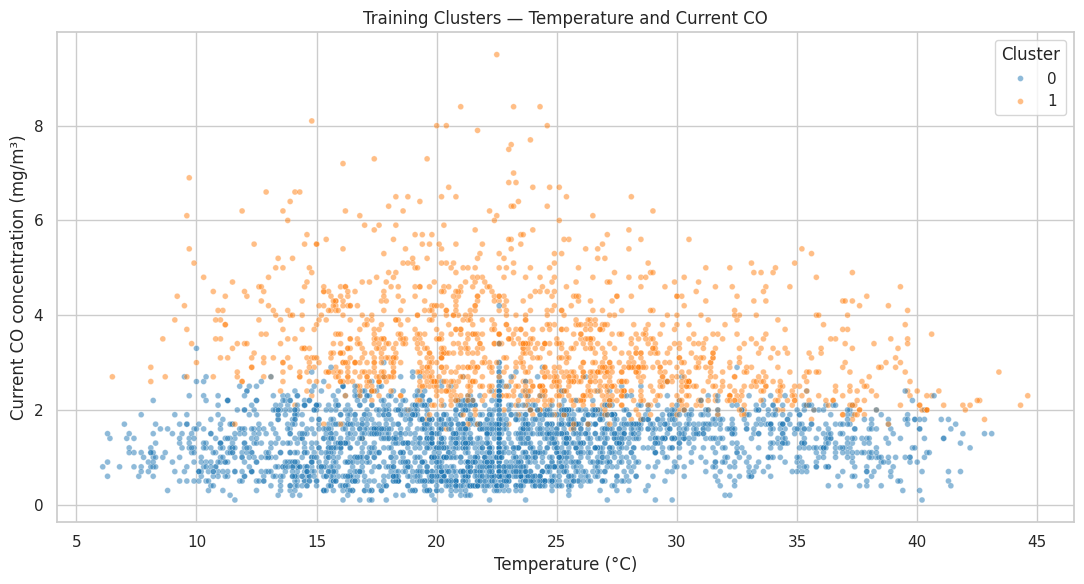

In [29]:
ts_cluster_profile_data = ts_X_train[ts_cluster_columns].copy()
ts_cluster_profile_data["cluster"] = ts_cluster_model.labels_

ts_cluster_profile = (
    ts_cluster_profile_data.groupby("cluster")
    [ts_cluster_columns].median().round(2)
)

ts_cluster_profile.insert(
    0,
    "observations",
    ts_cluster_profile_data.groupby("cluster").size()
)

display(ts_cluster_profile)

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=ts_cluster_profile_data,
    x="T_current",
    y="CO(GT)_current",
    hue="cluster",
    palette="tab10",
    alpha=0.5,
    s=18
)

plt.title("Training Clusters — Temperature and Current CO")
plt.xlabel("Temperature (°C)")
plt.ylabel("Current CO concentration (mg/m³)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Clustering Findings

Two clusters achieved the highest sampled silhouette score of 0.3471.

Cluster 0 contains 2,679 training observations with median current CO
of 1.3 mg/m³. Cluster 1 contains 1,473 observations with median current
CO of 3.1 mg/m³. Cluster 1 also has higher median benzene and NOx readings.

The groups broadly represent lower and higher pollution conditions.
They overlap across temperatures and summarize imputed predictor values.

## Anomaly Detection

Isolation Forest will identify unusual combinations of current pollutant,
sensor, and weather measurements using training data only. An initial
contamination setting of 1% defines the candidate filtering experiment.

Some flagged observations may be genuine pollution episodes. I will
retain the original training data and compare forecasting performance
with and without filtering. Validation and test observations remain
available for evaluation.

In [30]:
from sklearn.ensemble import IsolationForest

ts_anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

ts_anomaly_labels = ts_anomaly_model.fit_predict(
    ts_cluster_train_scaled
)

ts_anomaly_audit = ts_X_train[ts_cluster_columns].copy()
ts_anomaly_audit["cluster"] = ts_cluster_model.labels_
ts_anomaly_audit["is_anomaly"] = ts_anomaly_labels == -1
ts_anomaly_audit["anomaly_score"] = (
    ts_anomaly_model.decision_function(ts_cluster_train_scaled)
)

display(
    ts_anomaly_audit.groupby("is_anomaly").agg(
        observations=("CO(GT)_current", "size"),
        median_current_CO=("CO(GT)_current", "median"),
        median_temperature=("T_current", "median"),
        median_humidity=("RH_current", "median"),
        median_NOx=("NOx(GT)_current", "median")
    ).round(2)
)

display(
    ts_anomaly_audit.nsmallest(10, "anomaly_score")[
        [
            "CO(GT)_current",
            "T_current",
            "RH_current",
            "NOx(GT)_current",
            "anomaly_score"
        ]
    ]
)

ts_keep_mask = ts_anomaly_labels == 1

ts_X_train_filtered = ts_X_train.loc[ts_keep_mask].copy()
ts_y_train_filtered = ts_y_train.loc[ts_keep_mask].copy()

print("Original training rows:", len(ts_X_train))
print("Flagged training rows:", (~ts_keep_mask).sum())
print("Filtered training rows:", len(ts_X_train_filtered))

,observations,median_current_CO,median_temperature,median_humidity,median_NOx
is_anomaly,,,,,
False,4110,1.70,22.60,44.30,122.00
True,42,6.70,23.00,54.50,627.00


,CO(GT)_current,T_current,RH_current,NOx(GT)_current,anomaly_score
timestamp,,,,,
2004-10-20 17:00:00,8.00,24.60,58.90,895.00,-0.11
2004-10-26 18:00:00,9.50,22.50,61.50,952.00,-0.11
2004-10-26 17:00:00,8.40,23.20,58.70,918.00,-0.10
2004-10-25 17:00:00,7.90,21.70,61.90,814.00,-0.09
2004-10-25 18:00:00,8.40,21.00,64.90,860.00,-0.09
2004-10-20 18:00:00,7.70,23.90,61.80,826.00,-0.09
2004-10-25 19:00:00,8.00,20.00,68.60,820.00,-0.07
2004-10-22 18:00:00,8.40,24.30,54.30,686.00,-0.07
2004-03-17 19:00:00,7.60,23.10,26.50,411.00,-0.07


Original training rows: 4152
Flagged training rows: 42
Filtered training rows: 4110


## Anomaly Findings

Isolation Forest flagged 42 of 4,152 training observations. Flagged
observations had median current CO of 6.7 mg/m³ and median NOx of 627,
compared with 1.7 mg/m³ and 122 for the remaining observations.

Several flagged timestamps occur during consecutive evening hours.
They may represent genuine pollution episodes. I will compare models
trained with and without these observations before choosing whether
to retain the filtering.

In [31]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

def forecast_metrics(name, actual, predicted):
    return {
        "model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

ts_baseline_predictions = np.full(
    len(ts_y_val),
    ts_y_train.median()
)

ts_persistence_predictions = ts_X_val["CO(GT)_current"].to_numpy()

ts_preliminary_rows = [
    forecast_metrics(
        "Training-median baseline",
        ts_y_val,
        ts_baseline_predictions
    ),
    forecast_metrics(
        "Persistence baseline",
        ts_y_val,
        ts_persistence_predictions
    )
]

ts_ridge_models = {}

for name, features, target in [
    ("Ridge — original training", ts_X_train, ts_y_train),
    (
        "Ridge — filtered training",
        ts_X_train_filtered,
        ts_y_train_filtered
    )
]:
    model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0)
    )

    model.fit(features, target)
    predictions = np.maximum(model.predict(ts_X_val), 0)

    ts_ridge_models[name] = model
    ts_preliminary_rows.append(
        forecast_metrics(name, ts_y_val, predictions)
    )

ts_preliminary_results = pd.DataFrame(
    ts_preliminary_rows
).sort_values("MAE")

display(ts_preliminary_results.round(4))

,model,MAE,RMSE
1,Persistence baseline,0.61,0.92
2,Ridge — original training,0.64,0.90
3,Ridge — filtered training,0.64,0.91
0,Training-median baseline,1.41,1.98


## Preliminary Forecasting Results

Persistence achieved the lowest validation MAE of 0.6093 mg/m³.
Ridge trained on the original data achieved MAE of 0.6359 and slightly
lower RMSE of 0.8962.

Removing flagged observations increased Ridge MAE to 0.6385 and RMSE
to 0.9050. This experiment provides no evidence that anomaly filtering
improves forecasting, so subsequent modeling will retain all training rows.

In [32]:
from sklearn.feature_selection import SelectPercentile, f_regression

ts_selected_ridge = make_pipeline(
    SelectPercentile(
        score_func=f_regression,
        percentile=75
    ),
    StandardScaler(),
    Ridge(alpha=10.0)
)

ts_selected_ridge.fit(ts_X_train, ts_y_train)

ts_selected_predictions = np.maximum(
    ts_selected_ridge.predict(ts_X_val),
    0
)

ts_selector = ts_selected_ridge.steps[0][1]
ts_selected_columns = ts_X_train.columns[
    ts_selector.get_support()
].tolist()

ts_feature_ranking = pd.DataFrame({
    "feature": ts_X_train.columns,
    "score": ts_selector.scores_,
    "selected": ts_selector.get_support()
}).sort_values("score", ascending=False)

print("Original features:", ts_X_train.shape[1])
print("Selected features:", len(ts_selected_columns))

display(ts_feature_ranking.head(20))

ts_selection_comparison = pd.concat([
    ts_preliminary_results,
    pd.DataFrame([
        forecast_metrics(
            "Ridge — selected features",
            ts_y_val,
            ts_selected_predictions
        )
    ])
], ignore_index=True).sort_values("MAE")

display(ts_selection_comparison.round(4))

Original features: 54
Selected features: 40


,feature,score,selected
2,C6H6(GT)_current,"8,129.23",True
3,PT08.S2(NMHC)_current,"7,934.00",True
0,CO(GT)_current,"7,837.08",True
1,PT08.S1(CO)_current,"6,469.54",True
7,PT08.S4(NO2)_current,"4,564.22",True
8,PT08.S5(O3)_current,"4,534.77",True
4,NOx(GT)_current,"3,958.18",True
6,NO2(GT)_current,"3,298.69",True
5,PT08.S3(NOx)_current,"2,883.86",True
28,CO_mean_3h,"2,656.84",True


,model,MAE,RMSE
0,Persistence baseline,0.61,0.92
4,Ridge — selected features,0.62,0.88
1,Ridge — original training,0.64,0.90
2,Ridge — filtered training,0.64,0.91
3,Training-median baseline,1.41,1.98


## Feature Selection Results

Selecting 40 of 54 features improved Ridge validation MAE from 0.6359
to 0.6211 mg/m³ and RMSE from 0.8962 to 0.8804 mg/m³.

Current pollutant and sensor readings ranked highly, followed by recent
CO averages, historical CO readings, and calendar features.

Persistence remains the strongest model by validation MAE. I will next
compare AutoViML models using the original training rows and allow
AutoViML to perform its own feature selection.

The external validation period occurs strictly after training.
AutoViML's internal tuning is a tabular procedure and should not be
interpreted as chronological backtesting.

In [33]:
from pathlib import Path
import shutil
from google.colab import files

checkpoint_dir = Path("air_quality_checkpoint")
checkpoint_dir.mkdir(exist_ok=True)

for name, features, target in [
    ("train", ts_X_train, ts_y_train),
    ("validation", ts_X_val, ts_y_val),
    ("test", ts_X_test, ts_y_test)
]:
    saved = features.copy()
    saved["CO_next_hour"] = target
    saved.to_csv(checkpoint_dir / f"{name}.csv")

ts_selection_comparison.to_csv(
    checkpoint_dir / "comparison.csv", index=False
)

ts_feature_ranking.to_csv(
    checkpoint_dir / "feature_ranking.csv", index=False
)

ts_anomaly_audit.to_csv(checkpoint_dir / "anomaly_audit.csv")
ts_cluster_results.to_csv(
    checkpoint_dir / "cluster_scores.csv", index=False
)
ts_cluster_profile.to_csv(checkpoint_dir / "cluster_profiles.csv")

checkpoint_zip = shutil.make_archive(
    "air_quality_checkpoint",
    "zip",
    root_dir=checkpoint_dir
)

files.download(checkpoint_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
import sys
print(sys.version.split()[0])

3.12.13


In [35]:
%pip install --prefer-binary "numpy==1.26.4" "autoviml==0.2.2"

In [36]:
import io
import zipfile
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.metrics import mean_absolute_error, mean_squared_error
from autoviml.Auto_ViML import Auto_ViML

uploaded = files.upload()
archive = zipfile.ZipFile(io.BytesIO(next(iter(uploaded.values()))))

def restore_forecasts(name):
    frame = pd.read_csv(
        archive.open(f"{name}.csv"),
        index_col=0,
        parse_dates=True
    )
    target = frame.pop("CO_next_hour")
    return frame, target

ts_X_train, ts_y_train = restore_forecasts("train")
ts_X_val, ts_y_val = restore_forecasts("validation")
ts_X_test, ts_y_test = restore_forecasts("test")

ts_selection_comparison = pd.read_csv(
    archive.open("comparison.csv")
)

def forecast_metrics(name, actual, predicted):
    return {
        "model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }

print("AutoViML imported and forecast data restored.")
print("Training shape:", ts_X_train.shape)

Saving air_quality_checkpoint (2).zip to air_quality_checkpoint (2) (1).zip
AutoViML imported and forecast data restored.
Training shape: (4152, 54)


##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (4152, 55)
    Training Set Memory Usage = 1.74 MB
Test Set Shape = (1717, 54)
    Test Set Memory Usage = 0.71 MB
Single_Label Target: ['CO_next_hour']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  23
    Number of Integer-Categorical Columns =  0
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric

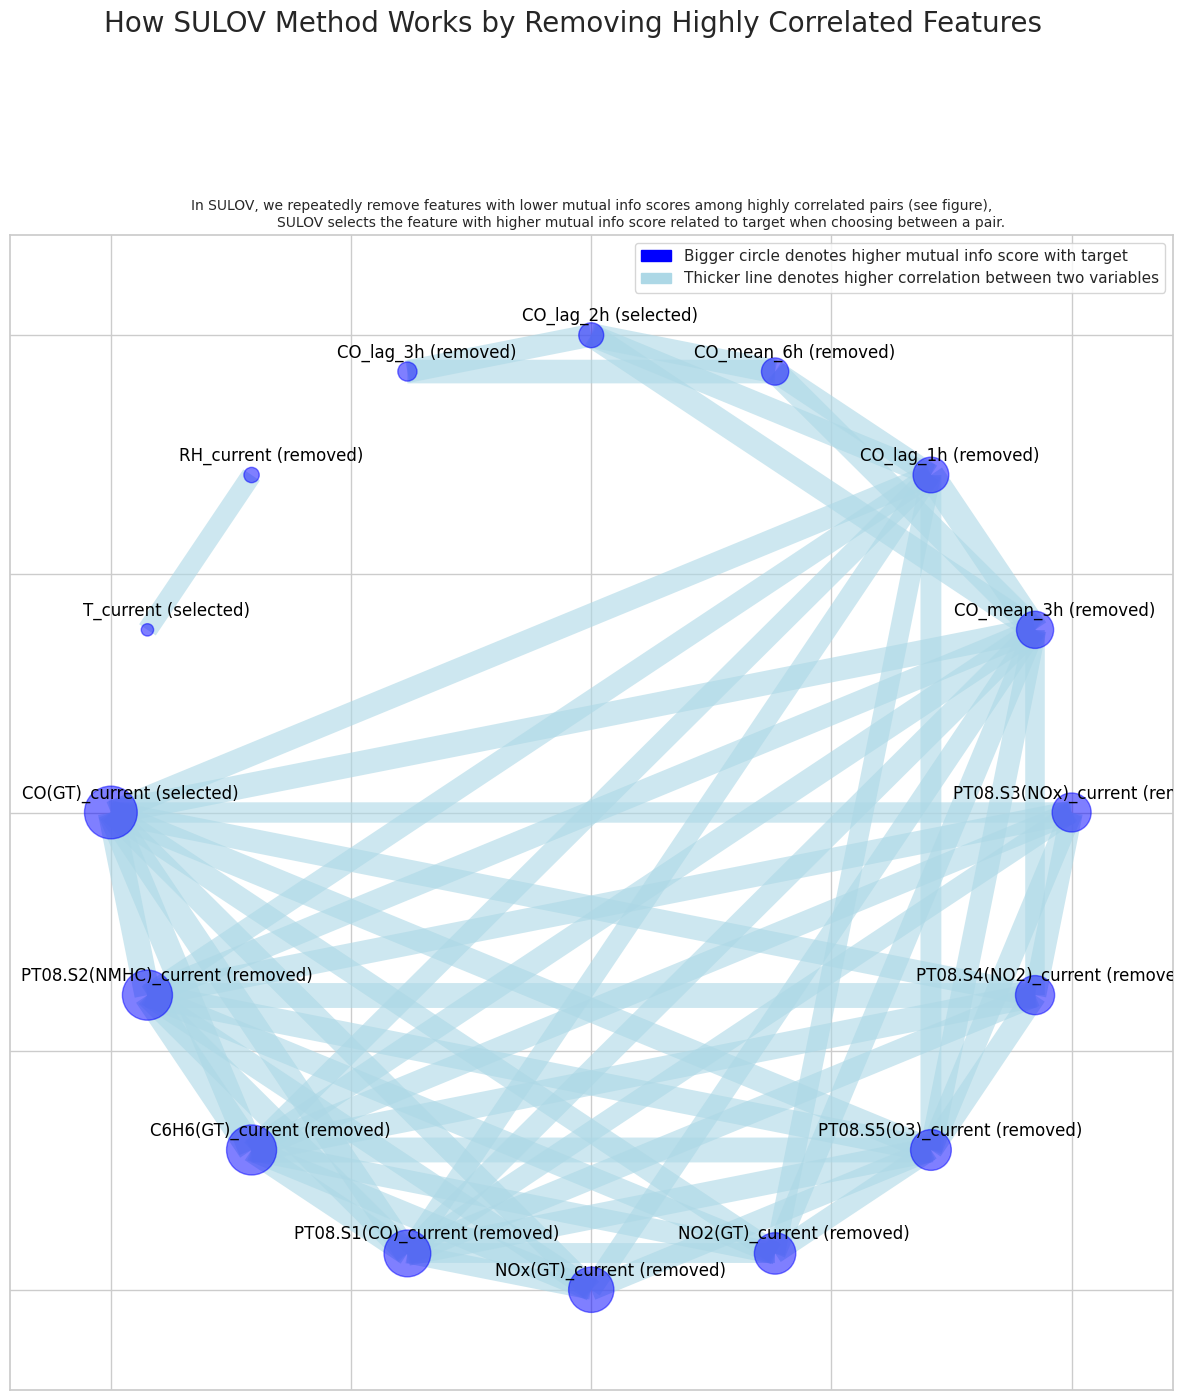

Splitting selected features into float and categorical (integer) variables:
    (10) float variables ...
    (31) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 41 
    Finding Important Features using Boosted Trees algorithm...
        using 41 variables...
        using 33 variables...
        using 25 variables...
        using 17 variables...
        using 9 variables...
Found 26 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  3321 , CV rows =  831
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling

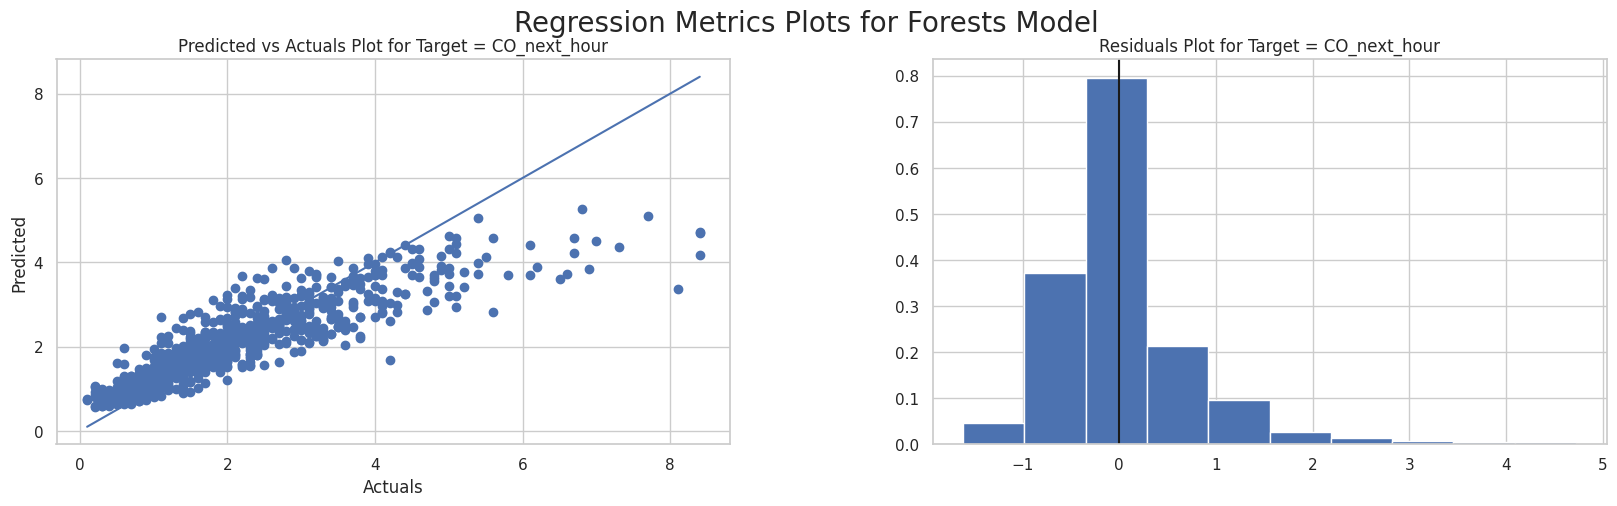

<Figure size 1500x1250 with 0 Axes>

In [37]:
ts_automl_train = ts_X_train.reset_index(drop=True).copy()
ts_automl_train["CO_next_hour"] = ts_y_train.to_numpy()

ts_automl_val = ts_X_val.reset_index(drop=True).copy()

ts_rf_model, ts_rf_features, ts_rf_train_modified, ts_rf_val_modified = Auto_ViML(
    train=ts_automl_train.copy(),
    target="CO_next_hour",
    test=ts_automl_val.copy(),
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="",
    Boosting_Flag=False,
    KMeans_Featurizer=False,
    Binning_Flag=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Imbalanced_Flag=False,
    GPU_flag=False,
    verbose=1
)

In [38]:
ts_rf_predictions = np.maximum(
    np.asarray(
        ts_rf_model.predict(
            ts_rf_val_modified[ts_rf_features]
        )
    ).reshape(-1),
    0
)

assert len(ts_rf_predictions) == len(ts_y_val)
assert np.isfinite(ts_rf_predictions).all()

ts_rf_results = pd.DataFrame([
    forecast_metrics(
        "AutoViML Random Forest",
        ts_y_val,
        ts_rf_predictions
    )
])

ts_model_comparison = pd.concat(
    [ts_selection_comparison, ts_rf_results],
    ignore_index=True
).sort_values("MAE")

display(ts_model_comparison.round(4))

,model,MAE,RMSE
0,Persistence baseline,0.61,0.92
1,Ridge — selected features,0.62,0.88
2,Ridge — original training,0.64,0.90
3,Ridge — filtered training,0.64,0.91
5,AutoViML Random Forest,0.71,1.07
4,Training-median baseline,1.41,1.98


##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (4152, 55)
    Training Set Memory Usage = 1.74 MB
Test Set Shape = (1717, 54)
    Test Set Memory Usage = 0.71 MB
Single_Label Target: ['CO_next_hour']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  23
    Number of Integer-Categorical Columns =  0
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric

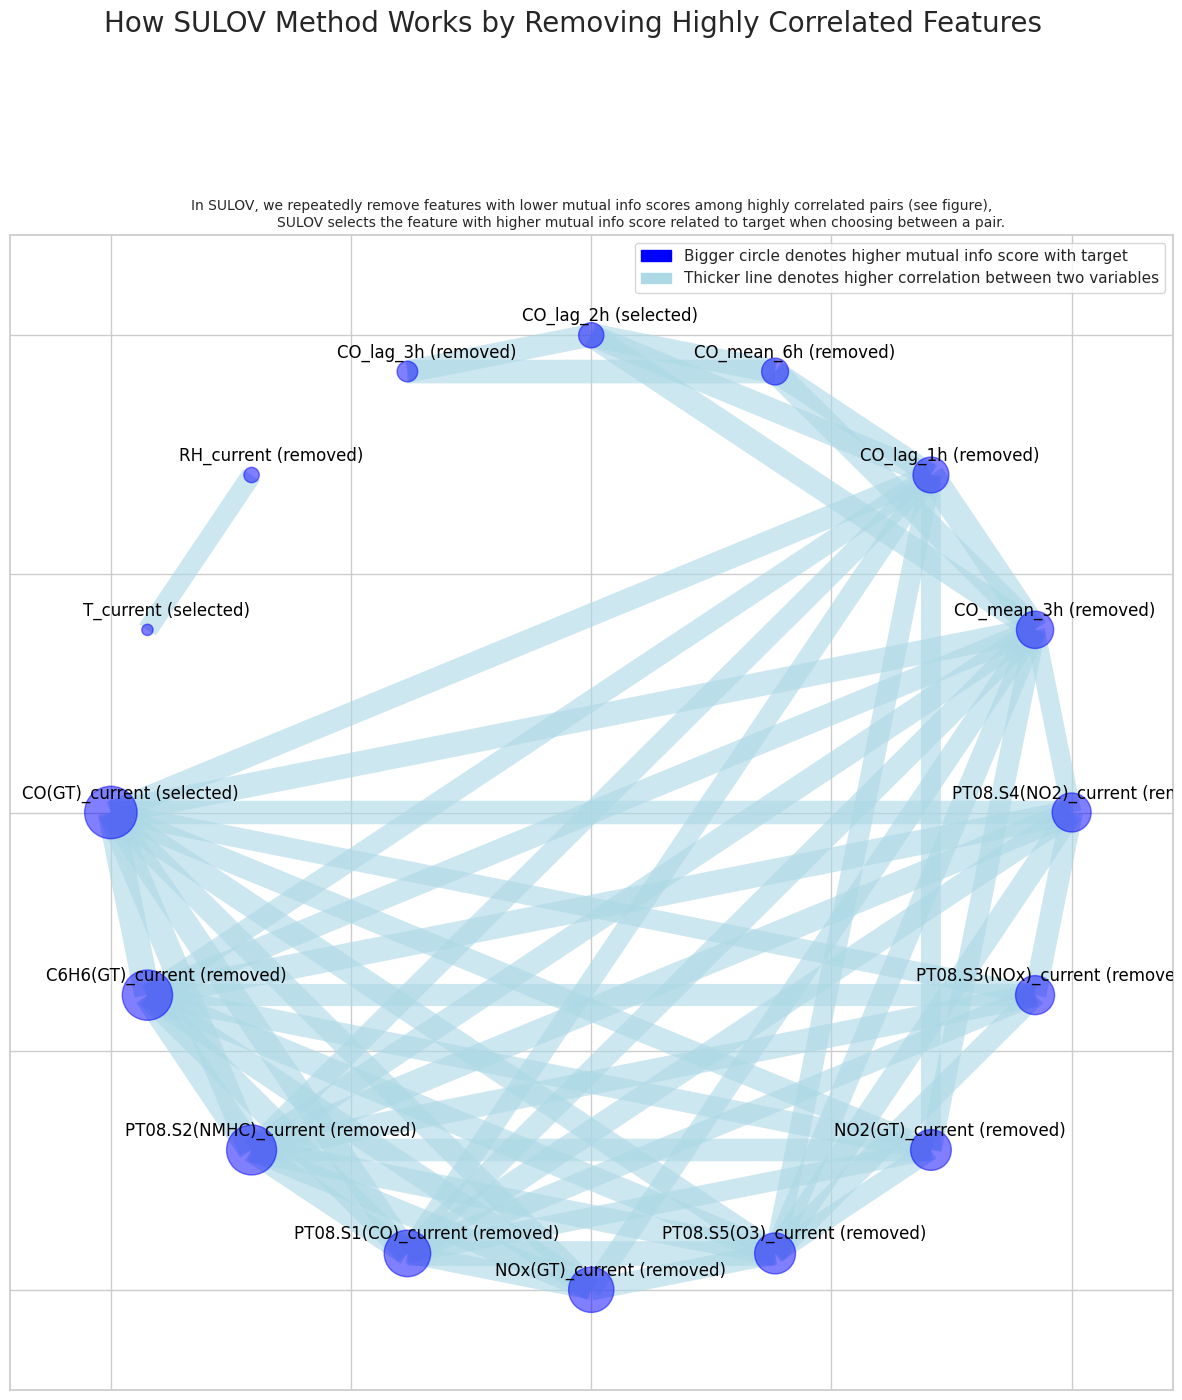

Splitting selected features into float and categorical (integer) variables:
    (10) float variables ...
    (31) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 41 
    Finding Important Features using Boosted Trees algorithm...
        using 41 variables...
        using 33 variables...
        using 25 variables...
        using 17 variables...
        using 9 variables...
Found 26 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  3321 , CV rows =  831
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Skipping MinMax scaling s

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Learning rate set to 0.01876
0:	learn: 1.2945603	test: 1.2766105	best: 1.2766105 (0)	total: 51ms	remaining: 5m 57s


500:	learn: 0.4852370	test: 0.5321149	best: 0.5321149 (500)	total: 1.27s	remaining: 16.5s
1000:	learn: 0.4254692	test: 0.5273882	best: 0.5273367 (992)	total: 2.88s	remaining: 17.2s
1500:	learn: 0.3833581	test: 0.5279264	best: 0.5268075 (1091)	total: 4.27s	remaining: 15.6s
2000:	learn: 0.3483162	test: 0.5298547	best: 0.5268075 (1091)	total: 5.28s	remaining: 13.2s
2500:	learn: 0.3187570	test: 0.5316140	best: 0.5268075 (1091)	total: 6.28s	remaining: 11.3s
3000:	learn: 0.2948342	test: 0.5336799	best: 0.5268075 (1091)	total: 7.48s	remaining: 9.97s
Stopped by overfitting detector  (2000 iterations wait)

bestTest = 0.5268075029
bestIteration = 1091

Shrink model to first 1092 iterations.
    Actual training time (in seconds): 8
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation RMSE Score = 0.5268
    CatBoost Best Parameters for Model: Iterations = 1091, learning_rate = 0.02
########################################################
CatBoost Model P

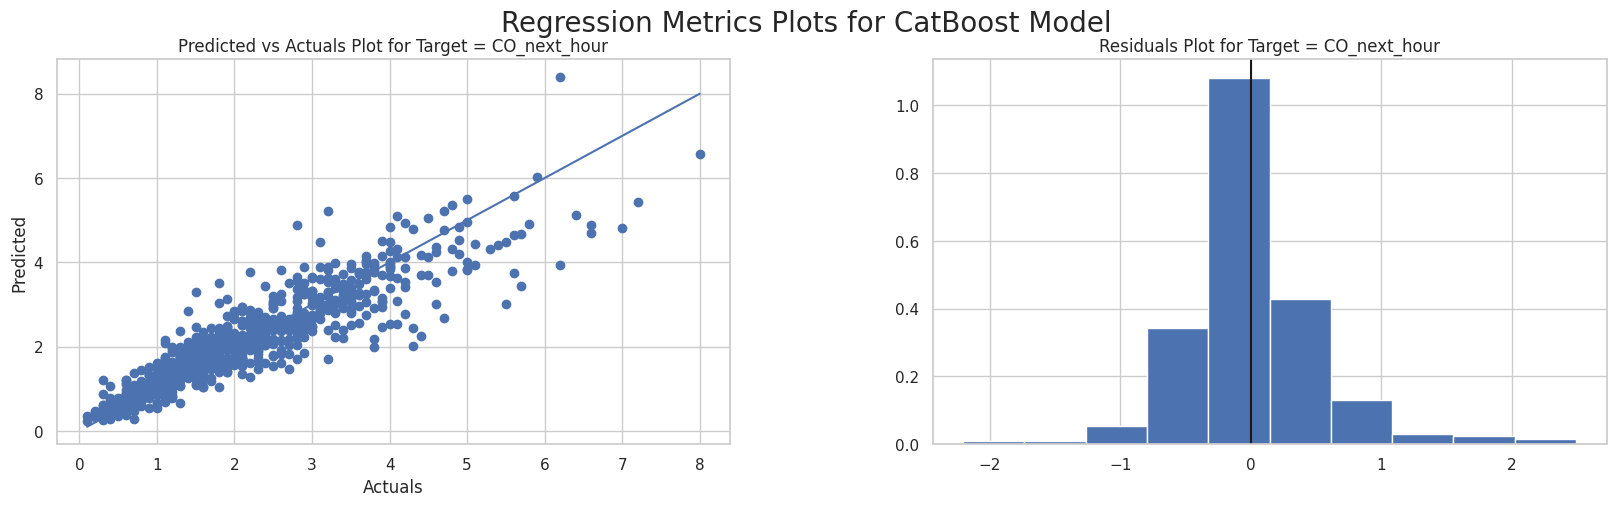

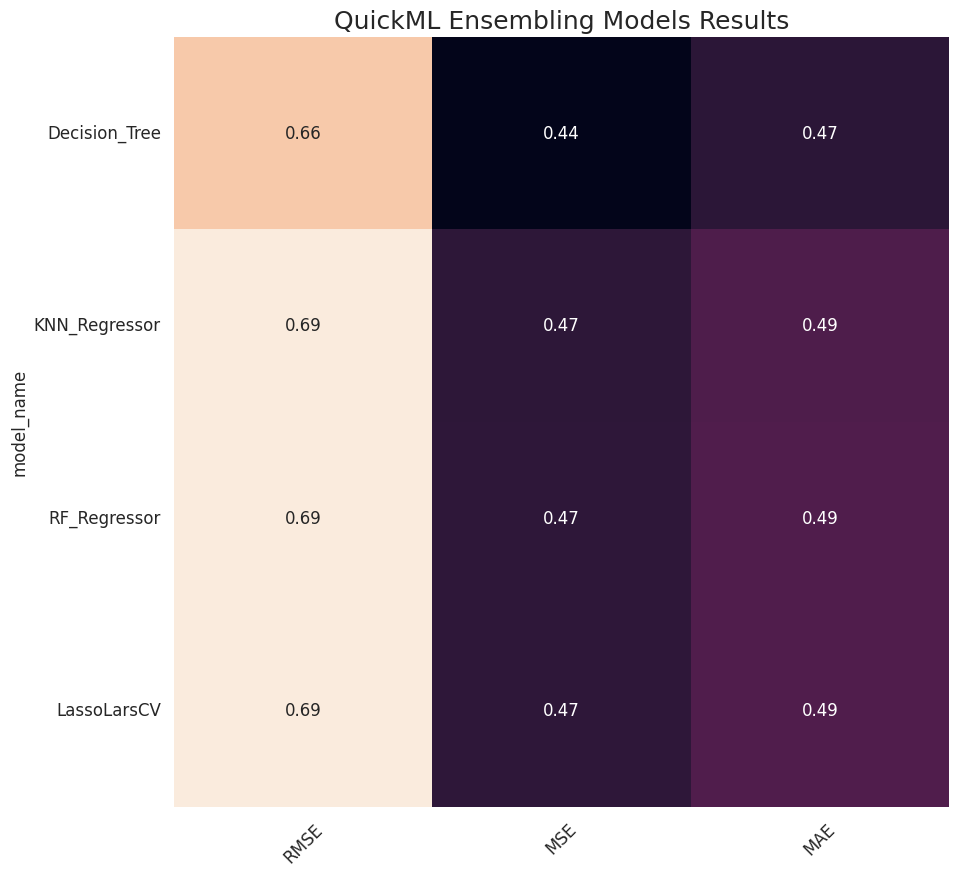

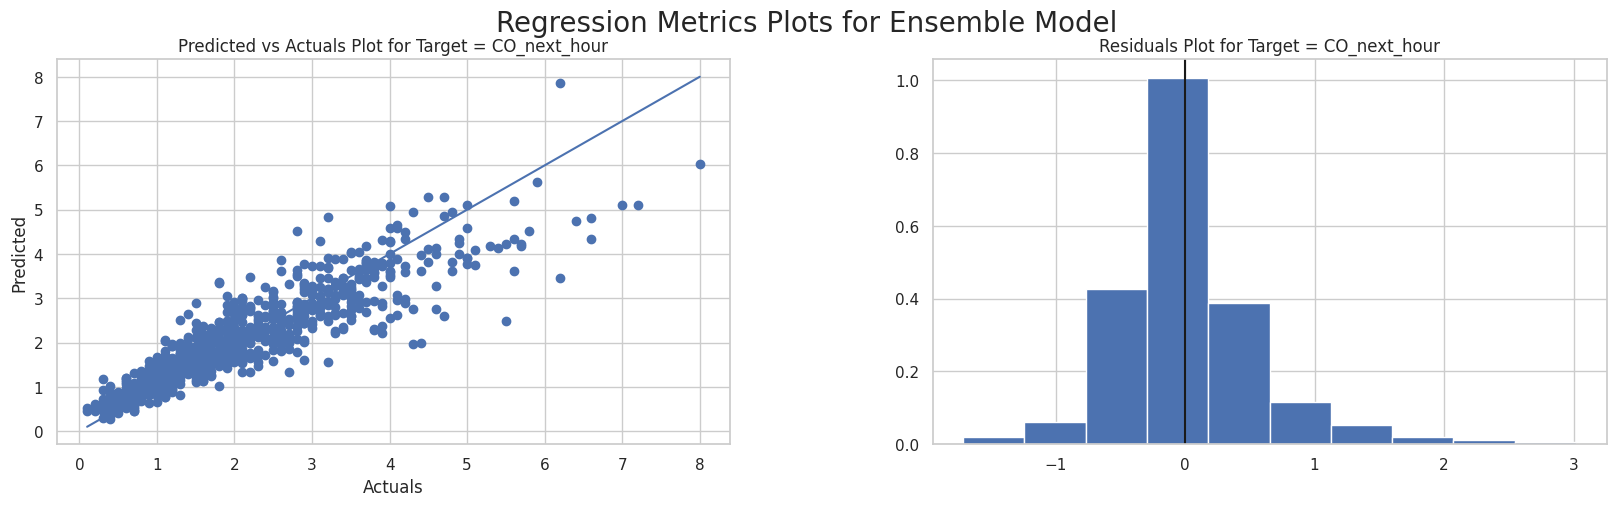

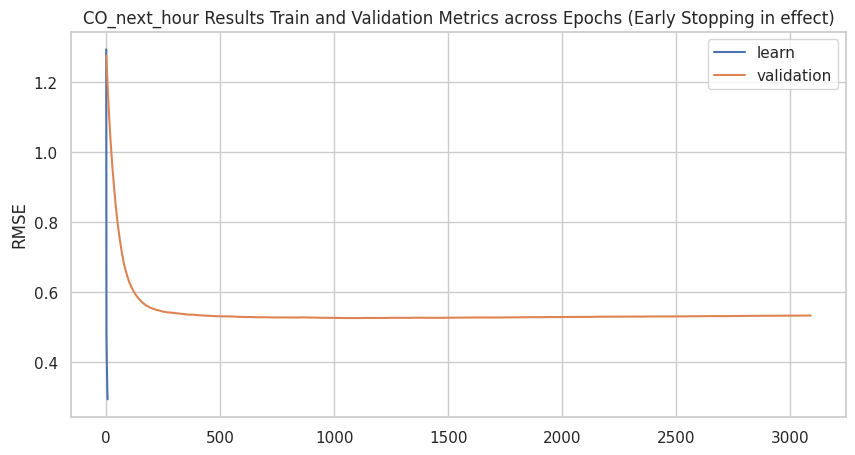

    Time taken for this Target (in seconds) = 14
    Binning_Flag set to False or there are no float vars in data set to be binned
    Setting best params for CatBoost model from Initial State since you cannot change params to a fitted Catboost model 
    Number of Categorical and Integer variables used in CatBoost training = 18
No MinMax scaling performed since scaling flag is set to false
###########################################################################
#####   F I N A L I Z I N G   M O D E L   O N    F U L L   T R A I N  #####
###########################################################################
0:	learn: 1.2910940	total: 4.03ms	remaining: 4.39s
500:	learn: 0.4892797	total: 1.85s	remaining: 2.18s
1000:	learn: 0.4375535	total: 4.03s	remaining: 363ms
1090:	learn: 0.4294794	total: 4.59s	remaining: 0us
     Actual Training time taken in seconds = 5
Training of models completed. Now starting predictions on test data...
    Calculating weighted average ensemble of 5 regres

In [39]:
ts_cat_model, ts_cat_features, ts_cat_train_modified, ts_cat_val_modified = Auto_ViML(
    train=ts_automl_train.copy(),
    target="CO_next_hour",
    test=ts_automl_val.copy(),
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="",
    Boosting_Flag="CatBoost",
    KMeans_Featurizer=False,
    Binning_Flag=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Imbalanced_Flag=False,
    GPU_flag=False,
    verbose=1
)

In [40]:
ts_cat_predictions = np.maximum(
    np.asarray(
        ts_cat_model.predict(
            ts_cat_val_modified[ts_cat_features]
        )
    ).reshape(-1),
    0
)

assert len(ts_cat_predictions) == len(ts_y_val)
assert np.isfinite(ts_cat_predictions).all()

ts_cat_results = pd.DataFrame([
    forecast_metrics(
        "AutoViML CatBoost",
        ts_y_val,
        ts_cat_predictions
    )
])

ts_model_comparison = pd.concat(
    [
        ts_selection_comparison,
        ts_rf_results,
        ts_cat_results
    ],
    ignore_index=True
).sort_values("MAE")

display(ts_model_comparison.round(4))

,model,MAE,RMSE
6,AutoViML CatBoost,0.57,0.83
0,Persistence baseline,0.61,0.92
1,Ridge — selected features,0.62,0.88
2,Ridge — original training,0.64,0.90
3,Ridge — filtered training,0.64,0.91
5,AutoViML Random Forest,0.71,1.07
4,Training-median baseline,1.41,1.98


## Model Selection

AutoViML CatBoost achieved the lowest chronological validation MAE,
approximately 0.57 mg/m³, compared with 0.61 for persistence.
Its RMSE was also lower, approximately 0.83 versus 0.92 mg/m³.

I selected the CatBoost configuration using validation MAE. Final
evaluation will use the later test period, with observed readings
becoming available each hour as specified in the forecasting setup.

##############  D A T A   S E T  A N A L Y S I S  #######################
Training Set Shape = (4152, 55)
    Training Set Memory Usage = 1.74 MB
Test Set Shape = (1781, 54)
    Test Set Memory Usage = 0.73 MB
Single_Label Target: ['CO_next_hour']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  23
    Number of Integer-Categorical Columns =  0
    Number of String-Categorical Columns =  0
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  0
    Number of Numeric

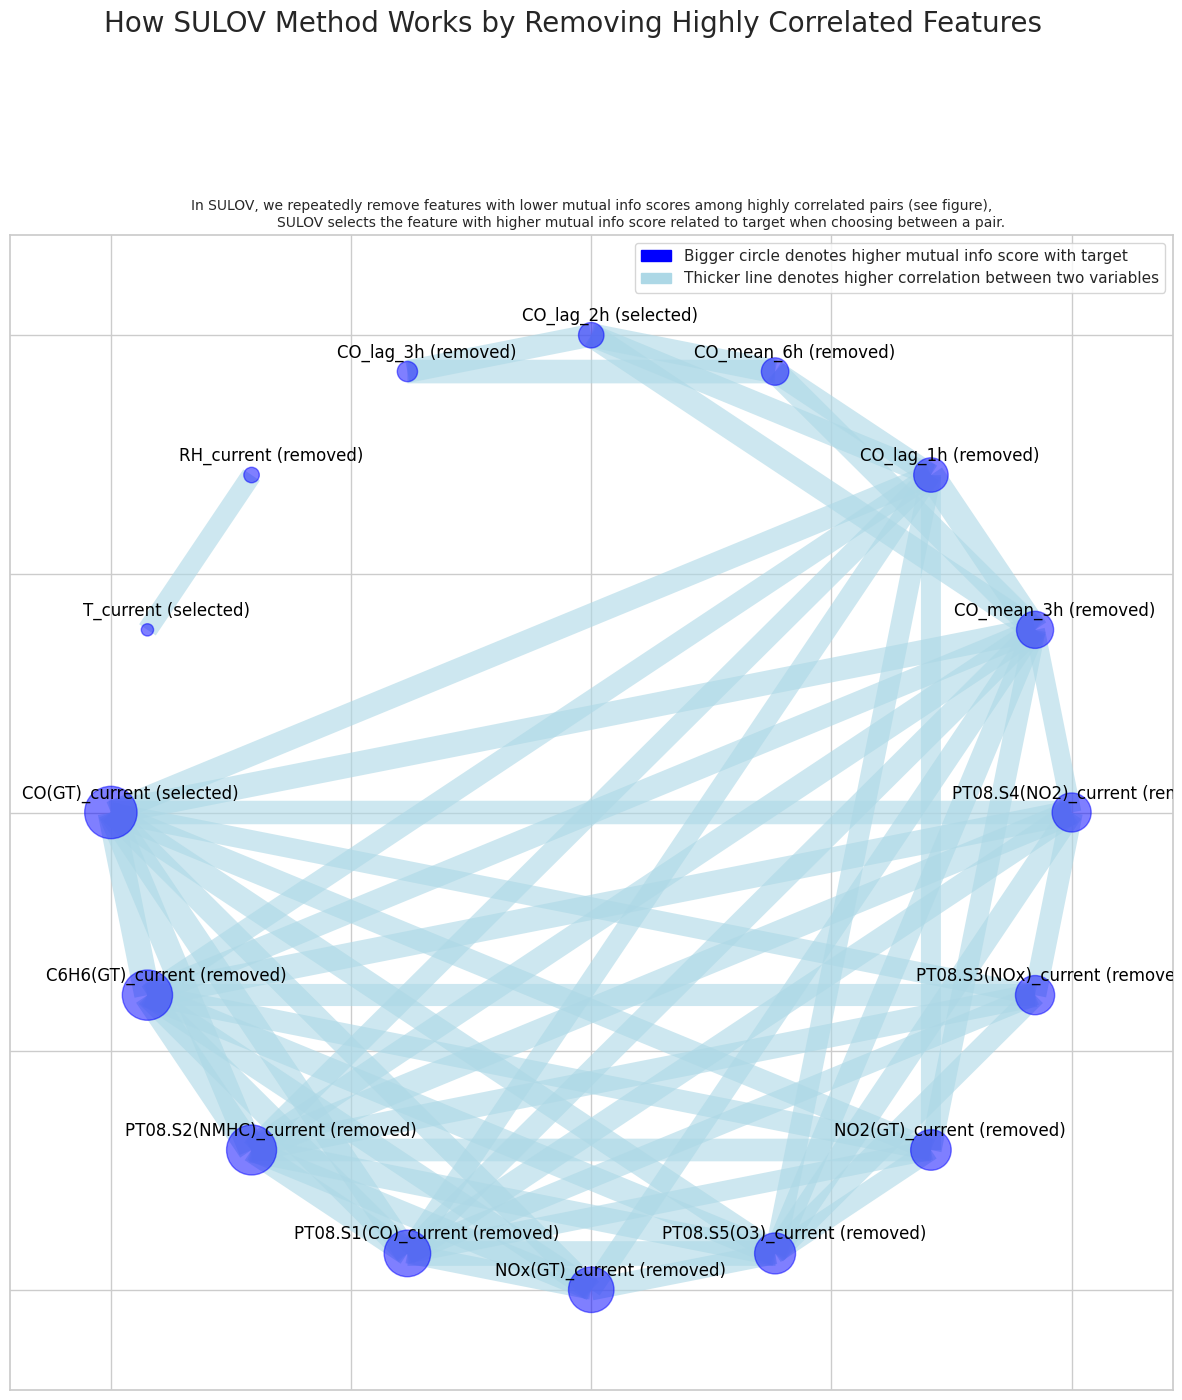

Splitting selected features into float and categorical (integer) variables:
    (10) float variables ...
    (31) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 41 
    Finding Important Features using Boosted Trees algorithm...
        using 41 variables...
        using 33 variables...
        using 25 variables...
        using 17 variables...
        using 9 variables...
Found 26 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  3321 , CV rows =  831
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Skipping MinMax scaling s

MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Learning rate set to 0.01876
0:	learn: 1.2896073	test: 1.2930358	best: 1.2930358 (0)	total: 11.7ms	remaining: 1m 21s


500:	learn: 0.4758506	test: 0.5666622	best: 0.5665248 (489)	total: 2.42s	remaining: 31.4s
1000:	learn: 0.4177980	test: 0.5660134	best: 0.5652271 (687)	total: 3.67s	remaining: 22s
1500:	learn: 0.3761574	test: 0.5675541	best: 0.5652271 (687)	total: 5.32s	remaining: 19.5s
2000:	learn: 0.3417638	test: 0.5682974	best: 0.5652271 (687)	total: 7.16s	remaining: 17.9s
2500:	learn: 0.3144634	test: 0.5707885	best: 0.5652271 (687)	total: 9.14s	remaining: 16.4s
Stopped by overfitting detector  (2000 iterations wait)

bestTest = 0.5652271165
bestIteration = 687

Shrink model to first 688 iterations.
    Actual training time (in seconds): 11
###########  Single_Label  M O D E L   R E S U L T S #################
5-fold Cross Validation RMSE Score = 0.5652
    CatBoost Best Parameters for Model: Iterations = 687, learning_rate = 0.02
########################################################
CatBoost Model Prediction Results on Held Out CV Data Set:
Regression Plots completed in 0.134 seconds
    MAE = 0.

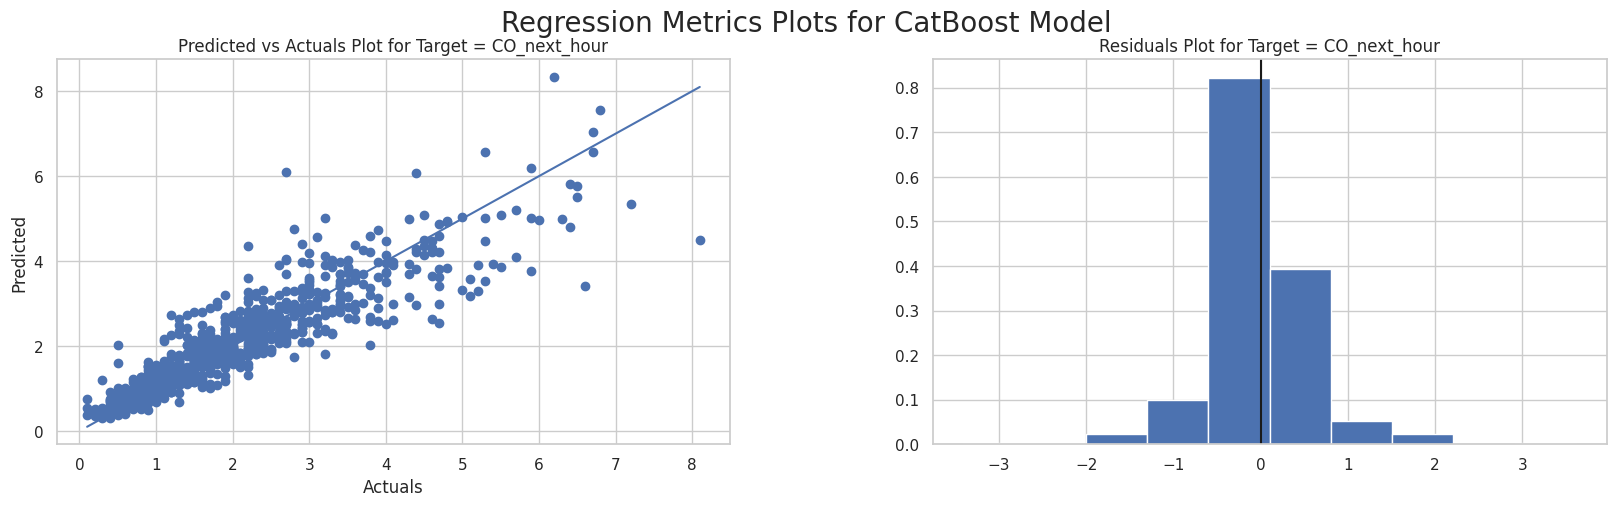

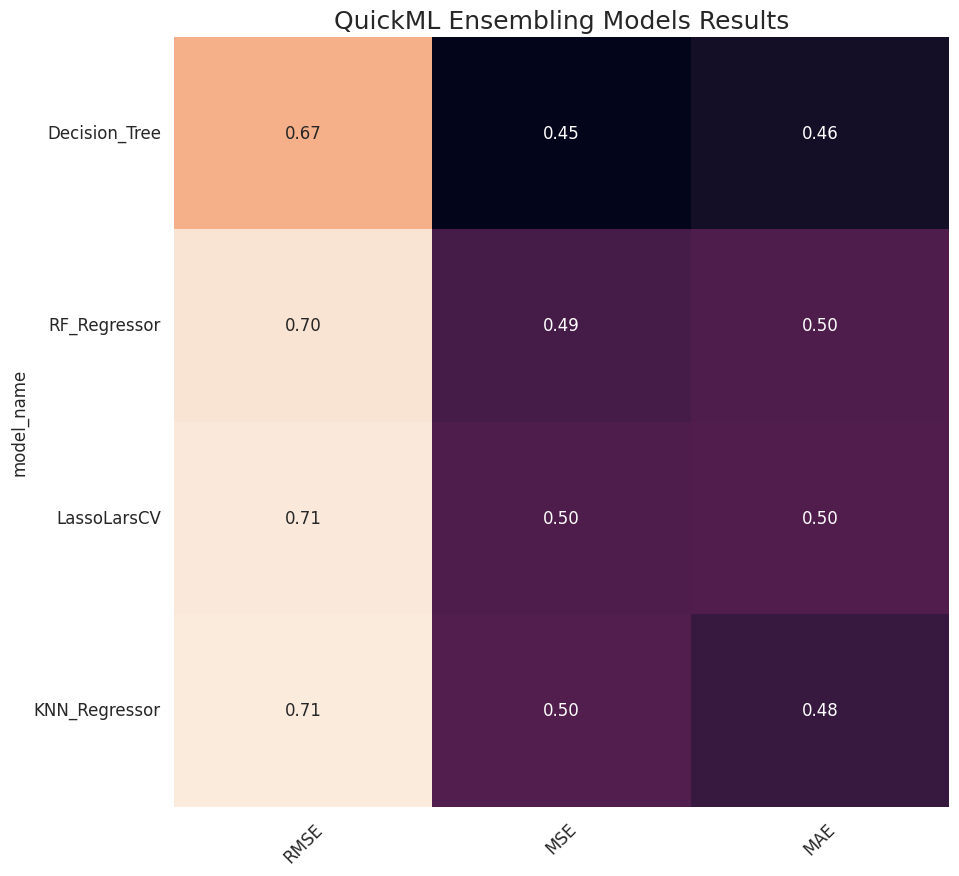

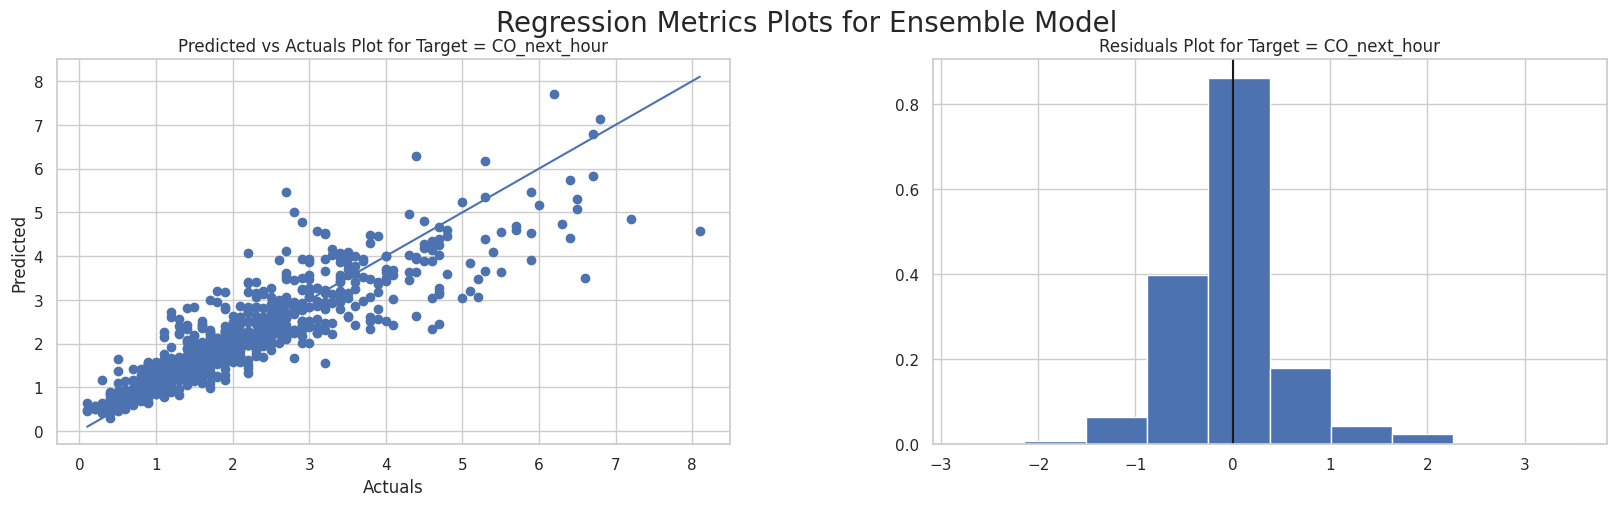

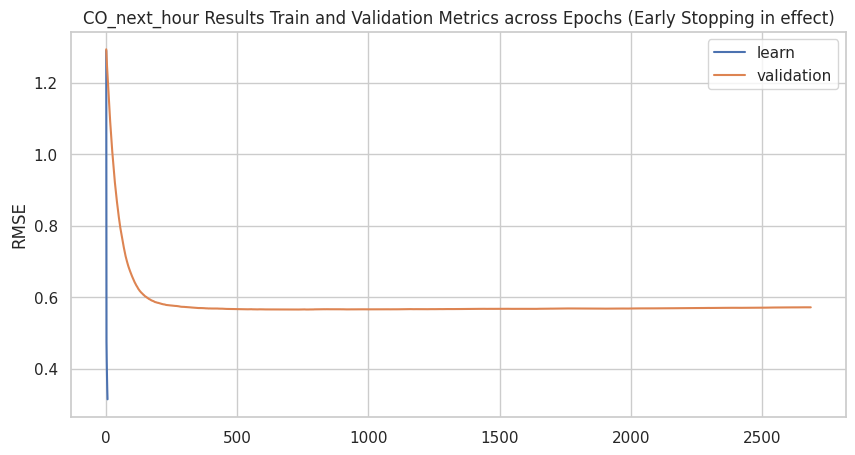

    Time taken for this Target (in seconds) = 19
    Binning_Flag set to False or there are no float vars in data set to be binned
    Setting best params for CatBoost model from Initial State since you cannot change params to a fitted Catboost model 
    Number of Categorical and Integer variables used in CatBoost training = 18
No MinMax scaling performed since scaling flag is set to false
###########################################################################
#####   F I N A L I Z I N G   M O D E L   O N    F U L L   T R A I N  #####
###########################################################################
0:	learn: 1.2910940	total: 2.53ms	remaining: 1.74s
500:	learn: 0.4898391	total: 1.16s	remaining: 432ms
686:	learn: 0.4690688	total: 1.56s	remaining: 0us
     Actual Training time taken in seconds = 2
Training of models completed. Now starting predictions on test data...
    Calculating weighted average ensemble of 5 regressors
Completed Ensemble predictions on held out data
 

In [41]:
ts_automl_test = ts_X_test.reset_index(drop=True).copy()

ts_final_model, ts_final_features, ts_final_train_modified, ts_final_test_modified = Auto_ViML(
    train=ts_automl_train.copy(),
    target="CO_next_hour",
    test=ts_automl_test.copy(),
    sample_submission="",
    hyper_param="RS",
    feature_reduction=True,
    scoring_parameter="",
    Boosting_Flag="CatBoost",
    KMeans_Featurizer=False,
    Binning_Flag=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Imbalanced_Flag=False,
    GPU_flag=False,
    verbose=1
)

In [42]:
ts_test_predictions = np.maximum(
    np.asarray(
        ts_final_model.predict(
            ts_final_test_modified[ts_final_features]
        )
    ).reshape(-1),
    0
)

assert len(ts_test_predictions) == len(ts_y_test)
assert np.isfinite(ts_test_predictions).all()

ts_test_persistence = ts_X_test["CO(GT)_current"].to_numpy()

ts_test_median = np.full(
    len(ts_y_test),
    ts_y_train.median()
)

ts_test_results = pd.DataFrame([
    forecast_metrics(
        "Training-median baseline",
        ts_y_test,
        ts_test_median
    ),
    forecast_metrics(
        "Persistence baseline",
        ts_y_test,
        ts_test_persistence
    ),
    forecast_metrics(
        "AutoViML CatBoost",
        ts_y_test,
        ts_test_predictions
    )
])

display(ts_test_results.round(4))

,model,MAE,RMSE
0,Training-median baseline,1.02,1.40
1,Persistence baseline,0.52,0.81
2,AutoViML CatBoost,0.44,0.65


## Final Test Results

On 1,781 observed next-hour targets in the final chronological test
period, AutoViML CatBoost achieved approximately 0.44 mg/m³ MAE and
0.65 mg/m³ RMSE. Persistence achieved approximately 0.52 MAE and
0.81 RMSE, while the training-median baseline achieved 1.02 and 1.40.

CatBoost outperformed both baselines in this test period. The workflow
assumes current-hour measurements become available before forecasting
the next hour. Missing target readings were excluded from evaluation.

Results apply to this historical sensor deployment. Performance at
other locations or during future periods remains unverified.

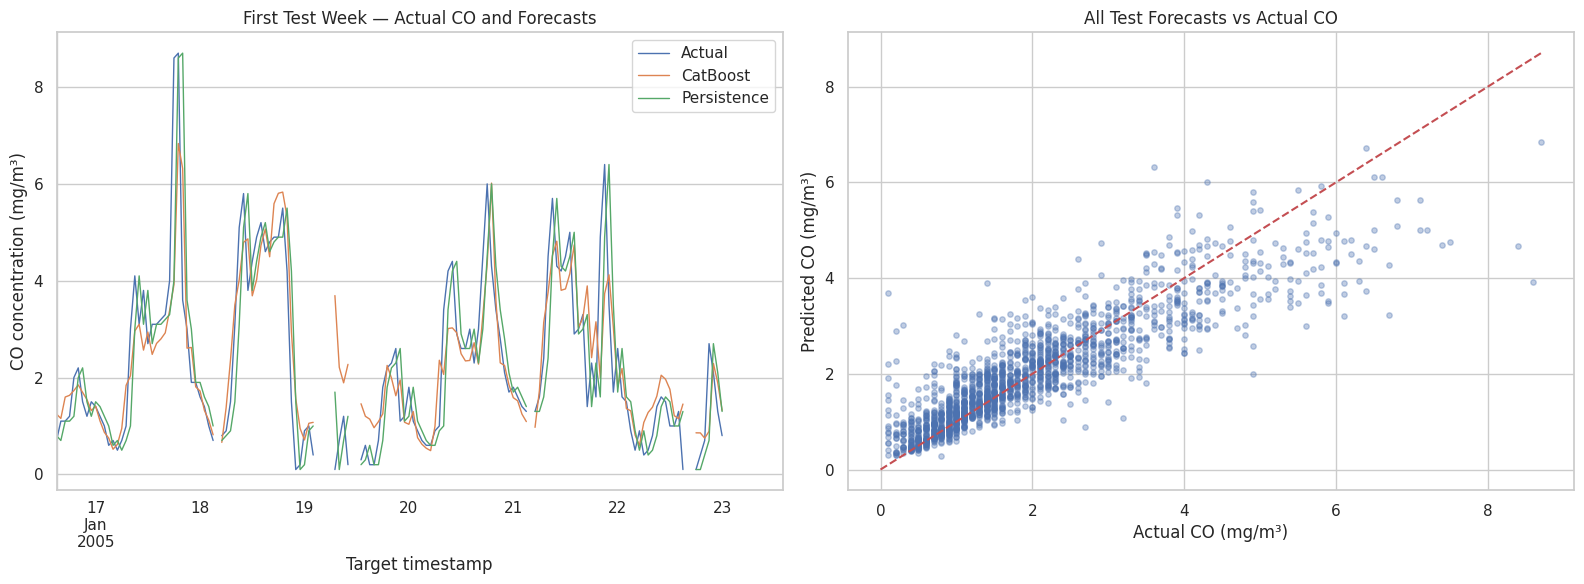

In [43]:
import matplotlib.pyplot as plt

ts_test_details = pd.DataFrame({
    "forecast_origin": ts_X_test.index,
    "target_timestamp": ts_X_test.index + pd.Timedelta(hours=1),
    "actual_CO": ts_y_test.to_numpy(),
    "predicted_CO": ts_test_predictions,
    "persistence_CO": ts_test_persistence
})

ts_test_details["residual"] = (
    ts_test_details["actual_CO"]
    - ts_test_details["predicted_CO"]
)

# Reindex to hourly timestamps so missing targets appear as gaps.
plot_data = (
    ts_test_details.set_index("target_timestamp")
    [["actual_CO", "predicted_CO", "persistence_CO"]]
    .asfreq("h")
)

first_week = plot_data.loc[
    plot_data.index.min():
    plot_data.index.min() + pd.Timedelta(days=7) - pd.Timedelta(hours=1)
]

ts_diagnostic_fig, axes = plt.subplots(1, 2, figsize=(16, 6))

first_week.plot(ax=axes[0], linewidth=1)
axes[0].set_title("First Test Week — Actual CO and Forecasts")
axes[0].set_xlabel("Target timestamp")
axes[0].set_ylabel("CO concentration (mg/m³)")
axes[0].legend(["Actual", "CatBoost", "Persistence"])

axes[1].scatter(
    ts_test_details["actual_CO"],
    ts_test_details["predicted_CO"],
    alpha=0.35,
    s=15
)

upper_limit = ts_test_details[
    ["actual_CO", "predicted_CO"]
].to_numpy().max()

axes[1].plot([0, upper_limit], [0, upper_limit], "r--")
axes[1].set_title("All Test Forecasts vs Actual CO")
axes[1].set_xlabel("Actual CO (mg/m³)")
axes[1].set_ylabel("Predicted CO (mg/m³)")

plt.tight_layout()
plt.show()

## Forecast Error Analysis

During the first test week, CatBoost follows many rises and falls in
observed CO. Several sharp peaks are underestimated.

The scatter plot shows predictions near the perfect-prediction line
for many lower concentrations, with greater spread at higher concentrations.
Despite these errors, CatBoost outperformed persistence on both test
MAE and RMSE.

In [44]:
from pathlib import Path
from importlib.metadata import version
import json
import shutil
import sys
import zipfile
from google.colab import files

output_dir = Path("air_quality_artifacts")
output_dir.mkdir(exist_ok=True)

ts_model_comparison.to_csv(
    output_dir / "validation_results.csv", index=False
)
ts_test_results.to_csv(
    output_dir / "test_results.csv", index=False
)
ts_test_details.to_csv(
    output_dir / "test_predictions.csv", index=False
)

for name, features, target in [
    ("train", ts_X_train, ts_y_train),
    ("validation", ts_X_val, ts_y_val),
    ("test", ts_X_test, ts_y_test)
]:
    prepared = features.copy()
    prepared["CO_next_hour"] = target
    prepared.to_csv(output_dir / f"prepared_{name}.csv")

audit_files = [
    "feature_ranking.csv",
    "anomaly_audit.csv",
    "cluster_scores.csv",
    "cluster_profiles.csv"
]

# Locate the checkpoint uploaded during restoration.
checkpoint_paths = sorted(
    Path(".").glob("air_quality_checkpoint*.zip")
)

if checkpoint_paths:
    with zipfile.ZipFile(checkpoint_paths[-1]) as checkpoint:
        for filename in audit_files:
            (output_dir / filename).write_bytes(
                checkpoint.read(filename)
            )
else:
    raise FileNotFoundError(
        "Upload air_quality_checkpoint.zip using Colab's Files panel, "
        "then rerun this cell."
    )

ts_diagnostic_fig.savefig(
    output_dir / "forecast_diagnostics.png",
    dpi=200,
    bbox_inches="tight"
)

environment = {
    "python": sys.version,
    "packages": {
        package: version(package)
        for package in [
            "numpy", "pandas", "scikit-learn",
            "autoviml", "catboost", "xgboost"
        ]
    },
    "selected_model": "AutoViML CatBoost",
    "target": "CO one hour ahead",
    "units": "mg/m3",
    "selected_features": list(ts_final_features),
    "evaluation": "Chronological holdout with hourly updated observations",
    "limitation": "AutoViML internal tuning uses tabular validation"
}

(output_dir / "environment_and_model.json").write_text(
    json.dumps(environment, indent=2)
)

archive_path = shutil.make_archive(
    "air_quality_artifacts",
    "zip",
    root_dir=output_dir
)

print("Exported files:")
for path in sorted(output_dir.iterdir()):
    print(path.name)

files.download(archive_path)

Exported files:
anomaly_audit.csv
cluster_profiles.csv
cluster_scores.csv
environment_and_model.json
feature_ranking.csv
forecast_diagnostics.png
prepared_test.csv
prepared_train.csv
prepared_validation.csv
test_predictions.csv
test_results.csv
validation_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>